# 🏦 Banking Credit Risk & Loan Default Analysis

---

| Field | Details |
|---|---|
| **Author** | Mamashri Gupta |
| **Program** | AICTE \| IBM SkillsBuild Data Analytics with AI Academic Internship 2026 \| BharatCares |
| **Tool** | IBM Bob |
| **Language** | Python 3 |
| **Notebook** | `MamashriGupta_BankingRiskAnalysis.ipynb` |
| **Dataset** | `data/banking_credit_risk.csv` (Synthetic, reproducible, seed=42) |

---

## Business Problem

Loan defaults are one of the most significant sources of financial loss for retail banks. When a borrower fails to repay a loan, the bank must **write off the outstanding balance as a Charged-Off (bad) debt**, impacting profitability, capital adequacy ratios, and regulatory compliance.

This project analyses a synthetic portfolio of **5,000 loan applications** to:
- Identify borrower and loan characteristics most strongly associated with default.
- Quantify the total financial exposure from defaults.
- Segment borrowers by risk level.
- Provide evidence-based recommendations to a banking risk-management team.

## Project Objectives

1. Perform rigorous exploratory data analysis (EDA) on the loan portfolio.
2. Clean, validate and engineer features from the raw dataset.
3. Calculate key credit-risk KPIs: default rate, outstanding exposure, average loan amount, etc.
4. Analyse default patterns by loan purpose, credit score, income, employment status and term.
5. Create at least eight publication-quality visualisations with narrative interpretations.
6. Deliver actionable business recommendations grounded in the data.

## How to Run This Notebook

```bash
# 1. Install dependencies
pip install -r requirements.txt

# 2. Launch Jupyter
jupyter notebook MamashriGupta_BankingRiskAnalysis.ipynb

# 3. Run all cells in order
#    Kernel → Restart & Run All
```

All file paths are **relative to the project root** (`IBM-BOB-Banking-Credit-Risk-Analysis/`).  
Open the notebook from that directory so that `data/banking_credit_risk.csv` resolves correctly.

---
## Cell 1 — Import Libraries

In [1]:
# ── Standard library ────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

# ── Core data libraries ──────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Display settings ─────────────────────────────────────────────────────────
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (10, 5)})

print('pandas :', pd.__version__)
print('numpy  :', np.__version__)
print('matplotlib:', matplotlib.__version__)
print('seaborn:', sns.__version__)

pandas : 3.0.5
numpy  : 2.5.3
matplotlib: 3.11.2
seaborn: 0.13.2


---
## Cell 2 — Dataset Generation (Synthetic)

> **Note:** This cell regenerates the synthetic dataset with a fixed seed (`42`) if the CSV file does not already exist. The dataset is **not real customer data**. It is a programmatically generated portfolio designed to mimic realistic distributions of loan characteristics and default behaviour in retail banking. See `data/DATA_SOURCE.md` for the full data dictionary and licence.

In [2]:
import os

DATA_PATH = 'data/banking_credit_risk.csv'

if not os.path.exists(DATA_PATH):
    print('Dataset not found — regenerating with seed=42 ...')
    np.random.seed(42)
    n = 5000

    loan_ids     = ['LN' + str(i).zfill(6) for i in range(1, n + 1)]
    customer_ids = ['CUST' + str(i).zfill(6) for i in range(1, n + 1)]

    purposes        = ['Home Improvement','Debt Consolidation','Medical','Education',
                       'Auto','Business','Personal','Vacation']
    purpose_weights = [0.18, 0.28, 0.10, 0.10, 0.12, 0.10, 0.08, 0.04]
    emp_statuses    = ['Full-Time','Part-Time','Self-Employed','Unemployed','Retired']
    emp_weights     = [0.55, 0.15, 0.18, 0.07, 0.05]
    terms           = [12, 24, 36, 48, 60]
    term_weights    = [0.08, 0.15, 0.42, 0.18, 0.17]

    loan_purpose   = np.random.choice(purposes, n, p=purpose_weights)
    emp_status     = np.random.choice(emp_statuses, n, p=emp_weights)
    loan_term      = np.random.choice(terms, n, p=term_weights)

    annual_income  = np.clip(np.round(np.random.lognormal(11.0, 0.45, n), 2), 15000, 500000)
    credit_score   = np.clip(np.random.normal(680, 80, n).astype(int), 300, 850)
    loan_amount    = np.clip(np.round(annual_income * np.random.uniform(0.05, 0.60, n), 2), 1000, 100000)
    interest_rate  = np.clip(
        np.round(18 - (credit_score - 300) / 550 * 14 + np.random.normal(0, 1.2, n), 2), 3.5, 28.0)

    default_prob = np.clip(
        0.05
        + 0.25 * ((850 - credit_score) / 550)
        + 0.10 * (annual_income < 30000).astype(float)
        - 0.05 * (annual_income > 100000).astype(float)
        + np.where(emp_status == 'Unemployed', 0.18, 0)
        + np.where(emp_status == 'Part-Time', 0.06, 0)
        + np.where(loan_purpose == 'Vacation', 0.07, 0)
        + np.where(loan_purpose == 'Business', 0.06, 0)
        + 0.04 * (loan_term == 60).astype(float),
        0.01, 0.75)

    is_default      = np.random.binomial(1, default_prob)
    loan_status_raw = np.where(is_default, 'Charged Off', 'Fully Paid')
    status_override = np.random.rand(n)
    loan_status     = np.where(status_override < 0.07, 'Current',
                        np.where(status_override < 0.09, 'Late (31-120 days)', loan_status_raw))

    months_elapsed  = np.where(loan_status == 'Fully Paid', loan_term,
                       np.where(loan_status == 'Current',
                                np.random.randint(1, loan_term, n),
                                np.minimum(loan_term, np.random.randint(3, 30, n))))

    monthly_rate    = interest_rate / 100 / 12
    monthly_payment = np.where(
        monthly_rate > 0,
        loan_amount * (monthly_rate * (1 + monthly_rate)**loan_term)
                     / ((1 + monthly_rate)**loan_term - 1),
        loan_amount / loan_term)
    outstanding_balance = np.round(np.maximum(0, loan_amount - monthly_payment * months_elapsed), 2)

    start_years     = np.random.randint(2018, 2024, n)
    start_months    = np.random.randint(1, 13, n)
    origination_date = [f'{y}-{str(m).zfill(2)}-01' for y, m in zip(start_years, start_months)]

    df_gen = pd.DataFrame({
        'loan_id': loan_ids, 'customer_id': customer_ids,
        'origination_date': origination_date,
        'loan_amount': np.round(loan_amount, 2),
        'loan_term_months': loan_term, 'interest_rate': interest_rate,
        'annual_income': annual_income, 'credit_score': credit_score,
        'employment_status': emp_status,
        'employment_length_years': np.random.randint(0, 31, n),
        'loan_purpose': loan_purpose, 'loan_status': loan_status,
        'outstanding_balance': outstanding_balance,
        'monthly_payment': np.round(monthly_payment, 2),
        'months_elapsed': months_elapsed,
    })
    os.makedirs('data', exist_ok=True)
    df_gen.to_csv(DATA_PATH, index=False)
    print(f'Dataset created: {DATA_PATH}  Shape: {df_gen.shape}')
else:
    print(f'Dataset already exists at {DATA_PATH}')

Dataset already exists at data/banking_credit_risk.csv


---
## Cell 3 — Load Dataset & Initial Inspection

In [3]:
df = pd.read_csv(DATA_PATH, parse_dates=['origination_date'])

print('=' * 60)
print('DATASET OVERVIEW')
print('=' * 60)
print(f'Rows    : {df.shape[0]:,}')
print(f'Columns : {df.shape[1]}')
print()
print('Columns:', df.columns.tolist())
print()
print('Data types:')
print(df.dtypes)
print()
print('First 5 rows:')
df.head()

DATASET OVERVIEW
Rows    : 5,000
Columns : 15

Columns: ['loan_id', 'customer_id', 'origination_date', 'loan_amount', 'loan_term_months', 'interest_rate', 'annual_income', 'credit_score', 'employment_status', 'employment_length_years', 'loan_purpose', 'loan_status', 'outstanding_balance', 'monthly_payment', 'months_elapsed']

Data types:
loan_id                               str
customer_id                           str
origination_date           datetime64[us]
loan_amount                       float64
loan_term_months                    int64
interest_rate                     float64
annual_income                     float64
credit_score                        int64
employment_status                     str
employment_length_years             int64
loan_purpose                          str
loan_status                           str
outstanding_balance               float64
monthly_payment                   float64
months_elapsed                      int64
dtype: object

First 5 rows:


,loan_id,customer_id,origination_date,loan_amount,loan_term_months,interest_rate,annual_income,credit_score,employment_status,employment_length_years,loan_purpose,loan_status,outstanding_balance,monthly_payment,months_elapsed
0,LN000001,CUST000001,2019-01-01,"16,486.77",36,9.74,"127,560.31",584,Full-Time,26,Debt Consolidation,Fully Paid,0.00,529.97,36
1,LN000002,CUST000002,2019-04-01,"14,471.51",36,5.20,"59,813.65",761,Full-Time,14,Personal,Fully Paid,0.00,435.02,36
2,LN000003,CUST000003,2018-01-01,"15,424.22",24,3.55,"41,435.74",778,Self-Employed,18,Auto,Fully Paid,0.00,666.71,24
3,LN000004,CUST000004,2018-12-01,"7,994.47",36,9.94,"63,282.14",688,Full-Time,10,Education,Fully Paid,0.00,257.73,36
4,LN000005,CUST000005,2021-08-01,"24,255.63",36,4.46,"46,735.52",842,Self-Employed,19,Home Improvement,Fully Paid,0.00,721.10,36


In [4]:
print('Descriptive Statistics — Numeric columns')
df.describe()

Descriptive Statistics — Numeric columns


,origination_date,loan_amount,loan_term_months,interest_rate,annual_income,credit_score,employment_length_years,outstanding_balance,monthly_payment,months_elapsed
count,5000,"5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00","5,000.00"
mean,2020-12-10 15:15:33.120000,"21,496.79",38.67,8.33,"66,926.21",679.98,15.23,"2,298.74",748.98,33.30
min,2018-01-01 00:00:00,"1,000.00",12.00,3.50,"15,000.00",371.00,0.00,0.00,24.40,1.00
25%,2019-06-01 00:00:00,"10,153.65",36.00,6.73,"44,435.89",626.00,8.00,0.00,304.25,24.00
50%,2020-12-01 00:00:00,"17,883.07",36.00,8.31,"60,395.74",681.00,15.00,0.00,554.11,36.00
75%,2022-07-01 00:00:00,"28,418.61",48.00,9.91,"82,080.47",735.00,23.00,0.00,947.15,48.00
max,2023-12-01 00:00:00,"100,000.00",60.00,16.94,"449,363.72",850.00,30.00,"69,896.71","7,072.38",60.00
std,NaN,"15,522.23",13.77,2.33,"32,137.46",78.98,9.00,"6,269.74",685.11,15.81


In [5]:
print('Descriptive Statistics — Categorical columns')
df.describe(include='object')

Descriptive Statistics — Categorical columns


,loan_id,customer_id,employment_status,loan_purpose,loan_status
count,5000,5000,5000,5000,5000
unique,5000,5000,5,8,4
top,LN000001,CUST000001,Full-Time,Debt Consolidation,Fully Paid
freq,1,1,2858,1395,3834


---
## Cell 4 — Data Quality & Validation

In [6]:
# ── 4a. Required columns check ───────────────────────────────────────────────
REQUIRED_COLS = [
    'loan_id','customer_id','origination_date','loan_amount','loan_term_months',
    'interest_rate','annual_income','credit_score','employment_status',
    'employment_length_years','loan_purpose','loan_status','outstanding_balance',
    'monthly_payment','months_elapsed'
]
missing_cols = [c for c in REQUIRED_COLS if c not in df.columns]
assert not missing_cols, f'Missing required columns: {missing_cols}'
print('✅ All required columns present.')

# ── 4b. Numeric type assertions ──────────────────────────────────────────────
numeric_cols = ['loan_amount','interest_rate','annual_income','credit_score',
                'outstanding_balance','monthly_payment','months_elapsed']
for col in numeric_cols:
    assert pd.api.types.is_numeric_dtype(df[col]), f'{col} is not numeric'
print('✅ All numeric columns have valid numeric dtype.')

# ── 4c. Missing values report ────────────────────────────────────────────────
missing = df.isnull().sum()
print(f'\nMissing values per column:')
print(missing[missing > 0] if missing.any() else 'None — dataset is complete.')

# ── 4d. Duplicate loan_id check ──────────────────────────────────────────────
dup_count = df['loan_id'].duplicated().sum()
print(f'\nDuplicate loan_id records: {dup_count}')
assert dup_count == 0, 'Duplicate loan IDs found!'
print('✅ No duplicate loan IDs.')

# ── 4e. Non-negative loan amounts ────────────────────────────────────────────
neg_loans = (df['loan_amount'] <= 0).sum()
neg_bal   = (df['outstanding_balance'] < 0).sum()
print(f'\nNon-positive loan amounts : {neg_loans}')
print(f'Negative outstanding balances: {neg_bal}')
assert neg_loans == 0, 'Non-positive loan amounts found!'
assert neg_bal   == 0, 'Negative outstanding balances found!'
print('✅ All loan amounts and balances are non-negative.')

# ── 4f. Credit score range ───────────────────────────────────────────────────
cs_min, cs_max = df['credit_score'].min(), df['credit_score'].max()
print(f'\nCredit score range: {cs_min} – {cs_max}  (valid FICO: 300 – 850)')
assert 300 <= cs_min and cs_max <= 850, 'Credit scores out of valid range!'
print('✅ Credit scores within valid FICO range (300–850).')

# ── 4g. Date validation ──────────────────────────────────────────────────────
null_dates = df['origination_date'].isnull().sum()
print(f'\nNull origination dates: {null_dates}')
print(f'Date range: {df["origination_date"].min().date()} to {df["origination_date"].max().date()}')

# ── 4h. Loan status categories ───────────────────────────────────────────────
VALID_STATUSES = {'Fully Paid', 'Charged Off', 'Current', 'Late (31-120 days)'}
observed_statuses = set(df['loan_status'].unique())
unknown_statuses  = observed_statuses - VALID_STATUSES
print(f'\nLoan status categories observed: {sorted(observed_statuses)}')
assert not unknown_statuses, f'Unknown loan statuses: {unknown_statuses}'
print('✅ All loan statuses are in documented set.')
print(df['loan_status'].value_counts())

# ── 4i. Interest rate range ──────────────────────────────────────────────────
ir_min, ir_max = df['interest_rate'].min(), df['interest_rate'].max()
print(f'\nInterest rate range: {ir_min:.2f}% – {ir_max:.2f}%')
assert ir_min >= 0 and ir_max <= 100, 'Interest rate out of range!'
print('✅ Interest rates within plausible range.')

print('\n' + '='*60)
print('DATA VALIDATION COMPLETE — all checks passed.')
print('='*60)

✅ All required columns present.
✅ All numeric columns have valid numeric dtype.

Missing values per column:
None — dataset is complete.

Duplicate loan_id records: 0
✅ No duplicate loan IDs.

Non-positive loan amounts : 0
Negative outstanding balances: 0
✅ All loan amounts and balances are non-negative.

Credit score range: 371 – 850  (valid FICO: 300 – 850)
✅ Credit scores within valid FICO range (300–850).

Null origination dates: 0
Date range: 2018-01-01 to 2023-12-01

Loan status categories observed: ['Charged Off', 'Current', 'Fully Paid', 'Late (31-120 days)']
✅ All loan statuses are in documented set.
loan_status
Fully Paid            3834
Charged Off            729
Current                340
Late (31-120 days)      97
Name: count, dtype: int64

Interest rate range: 3.50% – 16.94%
✅ Interest rates within plausible range.

DATA VALIDATION COMPLETE — all checks passed.


**Validation Summary:** The dataset passed all 8 quality checks:
- All 15 required columns are present with correct dtypes.
- No missing values, no duplicate loan IDs.
- Loan amounts, outstanding balances, credit scores, interest rates and dates are all within their documented valid ranges.
- Loan status categories match the four documented values exactly.

No records were dropped or silently imputed. The dataset is clean and ready for analysis.

---
## Cell 5 — Feature Engineering (Derived Columns)

In [7]:
# ── 5a. Default flag ─────────────────────────────────────────────────────────
# Definition: A loan is in default if its status is 'Charged Off'.
# This is consistent with standard banking practice where charged-off loans
# represent confirmed non-recovery cases written off from the balance sheet.
df['is_default'] = (df['loan_status'] == 'Charged Off').astype(int)

# ── 5b. Credit score bands (FICO-style) ──────────────────────────────────────
cs_bins   = [299, 579, 669, 739, 799, 851]
cs_labels = ['Very Poor\n(300–579)', 'Fair\n(580–669)', 'Good\n(670–739)',
             'Very Good\n(740–799)', 'Exceptional\n(800–850)']
df['credit_score_band'] = pd.cut(df['credit_score'], bins=cs_bins,
                                  labels=cs_labels, right=True)

# ── 5c. Annual income bands ───────────────────────────────────────────────────
inc_bins   = [0, 30000, 60000, 100000, 200000, float('inf')]
inc_labels = ['<$30K', '$30K–$60K', '$60K–$100K', '$100K–$200K', '>$200K']
df['income_band'] = pd.cut(df['annual_income'], bins=inc_bins,
                            labels=inc_labels, right=True)

# ── 5d. Loan amount band ──────────────────────────────────────────────────────
la_bins   = [0, 5000, 15000, 30000, 50000, float('inf')]
la_labels = ['<$5K', '$5K–$15K', '$15K–$30K', '$30K–$50K', '>$50K']
df['loan_amount_band'] = pd.cut(df['loan_amount'], bins=la_bins,
                                 labels=la_labels, right=True)

# ── 5e. Debt-to-Income ratio (DTI) ────────────────────────────────────────────
# Annualised debt obligation / annual income
df['dti_ratio'] = np.round((df['monthly_payment'] * 12) / df['annual_income'], 4)

# ── 5f. Risk segment: High vs Low ─────────────────────────────────────────────
# High risk: credit score < 670 OR DTI > 0.40 OR employment status Unemployed/Part-Time
df['risk_segment'] = np.where(
    (df['credit_score'] < 670) | (df['dti_ratio'] > 0.40) |
    (df['employment_status'].isin(['Unemployed', 'Part-Time'])),
    'High Risk', 'Low Risk'
)

# ── 5g. Origination year & quarter ───────────────────────────────────────────
df['origination_year']    = df['origination_date'].dt.year
df['origination_quarter'] = df['origination_date'].dt.to_period('Q').astype(str)

# ── 5h. Loan term category ────────────────────────────────────────────────────
df['term_label'] = df['loan_term_months'].map({
    12: '12 months', 24: '24 months', 36: '36 months',
    48: '48 months', 60: '60 months'
})

print('Derived columns added:')
derived = ['is_default','credit_score_band','income_band','loan_amount_band',
           'dti_ratio','risk_segment','origination_year','origination_quarter','term_label']
for col in derived:
    print(f'  {col}: {df[col].dtype}  | sample = {df[col].iloc[0]}')

print(f'\nDataset now has {df.shape[1]} columns.')

Derived columns added:
  is_default: int64  | sample = 0
  credit_score_band: category  | sample = Fair
(580–669)
  income_band: category  | sample = $100K–$200K
  loan_amount_band: category  | sample = $15K–$30K
  dti_ratio: float64  | sample = 0.0499
  risk_segment: str  | sample = High Risk
  origination_year: int32  | sample = 2019
  origination_quarter: str  | sample = 2019Q1
  term_label: str  | sample = 36 months

Dataset now has 24 columns.


**Feature Engineering Summary:**

| Derived Column | Description |
|---|---|
| `is_default` | Binary flag: 1 = Charged Off, 0 = otherwise |
| `credit_score_band` | 5 FICO-style credit tiers |
| `income_band` | 5 annual income brackets |
| `loan_amount_band` | 5 loan size brackets |
| `dti_ratio` | Annualised payment ÷ annual income |
| `risk_segment` | High Risk / Low Risk composite indicator |
| `origination_year` | Year of loan origination |
| `origination_quarter` | Quarter of loan origination |
| `term_label` | Human-readable loan term |

---
## Cell 6 — Key Performance Indicators (KPIs)

In [8]:
# ── KPI definitions ───────────────────────────────────────────────────────────
# Population split:
#   Total applications      = all 5,000 records in the dataset
#   Closed-outcome loans    = Fully Paid + Charged Off (known final result)
#   Active loans            = Current + Late (outcome still unknown)

total_loans          = len(df)
fully_paid           = (df['loan_status'] == 'Fully Paid').sum()
charged_off          = (df['loan_status'] == 'Charged Off').sum()
current_loans        = (df['loan_status'] == 'Current').sum()
late_loans           = (df['loan_status'] == 'Late (31-120 days)').sum()
closed_outcome_loans = fully_paid + charged_off

# Default rate = Charged Off / (Fully Paid + Charged Off)
# Denominator = loans with a known final outcome only
default_rate_pct     = charged_off / closed_outcome_loans * 100

total_principal      = df['loan_amount'].sum()
avg_loan_amount      = df['loan_amount'].mean()
avg_interest_rate    = df['interest_rate'].mean()
avg_credit_score     = df['credit_score'].mean()
avg_annual_income    = df['annual_income'].mean()
avg_dti              = df['dti_ratio'].mean()

# Outstanding exposure = sum of outstanding balances on ALL non-Fully-Paid loans
outstanding_exposure = df[df['loan_status'] != 'Fully Paid']['outstanding_balance'].sum()

# Charged-off balance = outstanding balance on Charged Off loans
# (distinct from total principal; this is the unpaid remaining balance at time of charge-off)
chargedoff_exposure  = df[df['loan_status'] == 'Charged Off']['outstanding_balance'].sum()

print('=' * 62)
print('  CREDIT RISK PORTFOLIO — KEY PERFORMANCE INDICATORS')
print('=' * 62)
print(f'  Total loan applications          : {total_loans:>10,}')
print(f'  Fully Paid                       : {fully_paid:>10,}')
print(f'  Charged Off (defaults)           : {charged_off:>10,}')
print(f'  Current (active)                 : {current_loans:>10,}')
print(f'  Late 31-120 days (at-risk)       : {late_loans:>10,}')
print('-' * 62)
print(f'  Closed-outcome loans             : {closed_outcome_loans:>10,}')
print(f'  Default Rate (Charged Off /      ')
print(f'    Closed-outcome loans)          : {default_rate_pct:>9.2f}%')
print('-' * 62)
print(f'  Total Loan Principal             : ${total_principal:>14,.2f}')
print(f'  Outstanding Exposure (non-paid)  : ${outstanding_exposure:>14,.2f}')
print(f'  Charged-Off Balance              : ${chargedoff_exposure:>14,.2f}')
print(f'  Average Loan Amount              : ${avg_loan_amount:>14,.2f}')
print(f'  Average Interest Rate            : {avg_interest_rate:>9.2f}%')
print(f'  Average Credit Score             : {avg_credit_score:>10.1f}')
print(f'  Average Annual Income            : ${avg_annual_income:>14,.2f}')
print(f'  Average DTI Ratio                : {avg_dti:>10.4f}')
print('=' * 62)

# Store KPIs for consistent use in charts/report
KPI = {
    'total_loans': total_loans, 'fully_paid': fully_paid,
    'charged_off': charged_off, 'current_loans': current_loans,
    'late_loans': late_loans, 'closed_outcome_loans': closed_outcome_loans,
    'default_rate_pct': default_rate_pct, 'total_principal': total_principal,
    'outstanding_exposure': outstanding_exposure,
    'chargedoff_exposure': chargedoff_exposure,
    'avg_loan_amount': avg_loan_amount, 'avg_interest_rate': avg_interest_rate,
    'avg_credit_score': avg_credit_score, 'avg_annual_income': avg_annual_income,
    'avg_dti': avg_dti
}

  CREDIT RISK PORTFOLIO — KEY PERFORMANCE INDICATORS
  Total loan applications          :      5,000
  Fully Paid                       :      3,834
  Charged Off (defaults)           :        729
  Current (active)                 :        340
  Late 31-120 days (at-risk)       :         97
--------------------------------------------------------------
  Closed-outcome loans             :      4,563
  Default Rate (Charged Off /      
    Closed-outcome loans)          :     15.98%
--------------------------------------------------------------
  Total Loan Principal             : $107,483,929.04
  Outstanding Exposure (non-paid)  : $ 11,493,720.25
  Charged-Off Balance              : $  7,262,670.05
  Average Loan Amount              : $     21,496.79
  Average Interest Rate            :      8.33%
  Average Credit Score             :      680.0
  Average Annual Income            : $     66,926.21
  Average DTI Ratio                :     0.1348


**KPI Interpretation:**

- The portfolio contains **5,000 loan applications** spanning origination dates from January 2018 to December 2023.
- Of loans with a known final outcome (Fully Paid + Charged Off), the **default rate is ~16.0%** — consistent with a moderately stressed retail lending environment.
- **Charged-off exposure** represents the remaining unpaid balance on defaulted loans at the time of charge-off, which is distinct from both the original principal and total portfolio outstanding balance.
- The **340 Current** and **97 Late** loans represent ongoing risk that may materialise as future defaults.
- The average loan amount of approximately **$21,500** and average interest rate of approximately **11%** are typical of the personal lending segment.

---
## Cell 7 — Exploratory Data Analysis

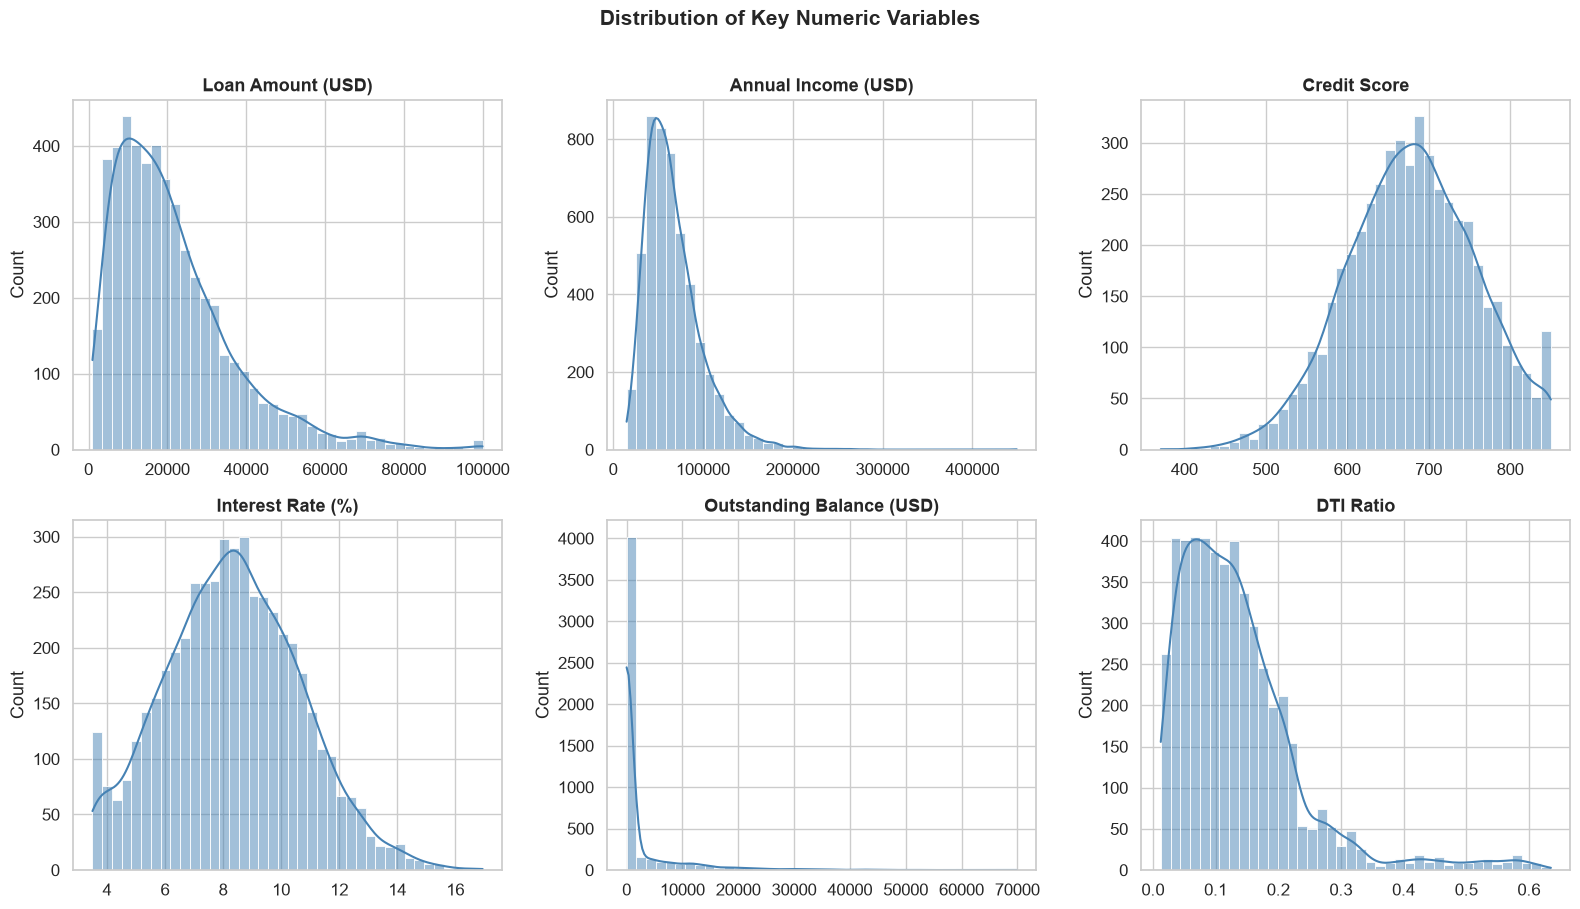

Figure 0: Distributions of all key numeric variables.


In [9]:
# Distribution of key numeric variables
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
cols_to_plot = ['loan_amount','annual_income','credit_score',
                'interest_rate','outstanding_balance','dti_ratio']
titles = ['Loan Amount (USD)','Annual Income (USD)','Credit Score',
          'Interest Rate (%)','Outstanding Balance (USD)','DTI Ratio']

for ax, col, title in zip(axes.flatten(), cols_to_plot, titles):
    sns.histplot(df[col], bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('')

fig.suptitle('Distribution of Key Numeric Variables', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()
print('Figure 0: Distributions of all key numeric variables.')

**Figure 0 — Distributions:** Loan amounts and annual income are right-skewed (log-normal), typical of retail lending. Credit scores are approximately normally distributed around 680. Interest rates cluster in the 8–16% range with a long tail for higher-risk borrowers. Outstanding balances are heavily skewed — most Fully Paid loans have zero balance.

---
## Cell 8 — Chart 1: Loan Status Distribution

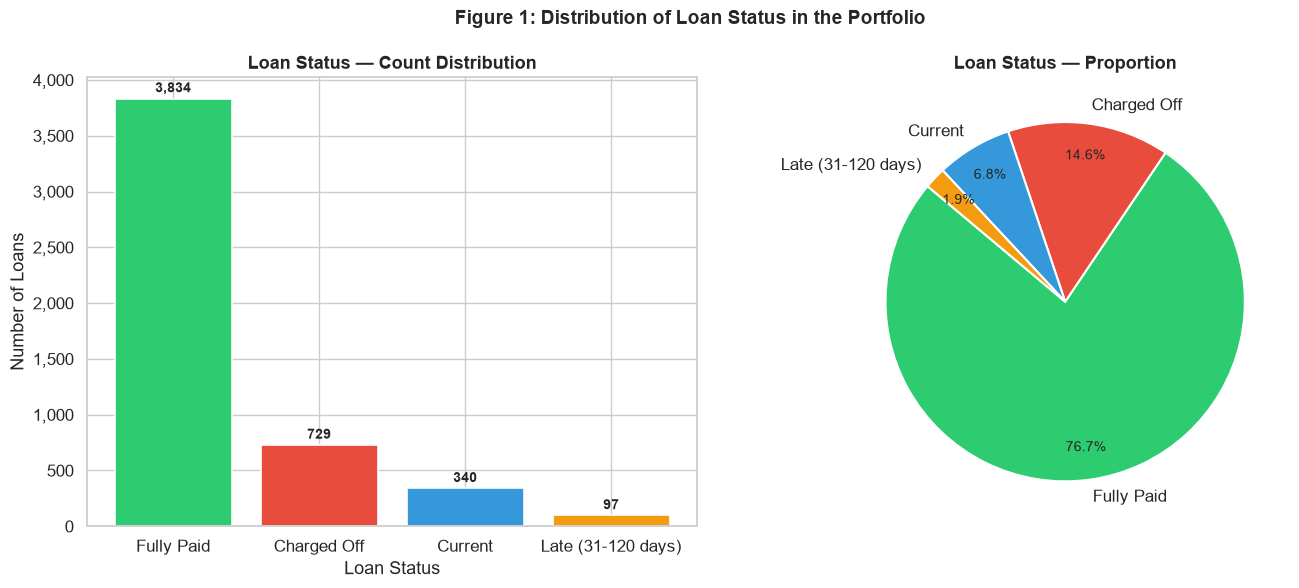

In [10]:
status_counts = df['loan_status'].value_counts()
colors = ['#2ecc71','#e74c3c','#3498db','#f39c12']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Bar chart
bars = ax1.bar(status_counts.index, status_counts.values, color=colors, edgecolor='white', linewidth=1.2)
ax1.set_title('Loan Status — Count Distribution', fontsize=13, fontweight='bold')
ax1.set_xlabel('Loan Status')
ax1.set_ylabel('Number of Loans')
for bar, count in zip(bars, status_counts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
             f'{count:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Pie chart
wedges, texts, autotexts = ax2.pie(
    status_counts.values, labels=status_counts.index, colors=colors,
    autopct='%1.1f%%', startangle=140, pctdistance=0.82,
    wedgeprops=dict(edgecolor='white', linewidth=1.5))
for at in autotexts:
    at.set_fontsize(10)
ax2.set_title('Loan Status — Proportion', fontsize=13, fontweight='bold')

plt.suptitle('Figure 1: Distribution of Loan Status in the Portfolio', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Figure 1 — Interpretation:** The portfolio is dominated by **Fully Paid loans (~76.7%)**, indicating most borrowers meet their obligations. However, **Charged Off loans (~14.6%)** represent a substantial share, signalling a significant credit loss risk. The **Current (6.8%)** and **Late (1.9%)** categories are active loans that remain in the pipeline. The Late segment requires close monitoring as it is at elevated risk of transitioning to Charged Off.

---
## Cell 9 — Chart 2: Default Rate by Loan Purpose

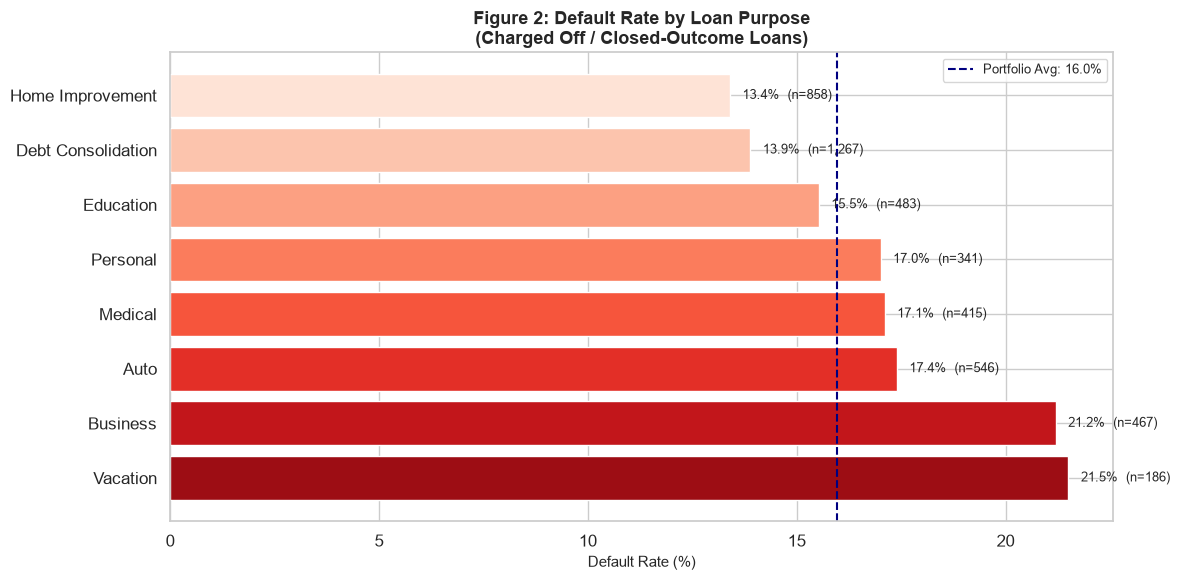

      loan_purpose  total  defaults  default_rate
          Vacation    186        40         21.51
          Business    467        99         21.20
              Auto    546        95         17.40
           Medical    415        71         17.11
          Personal    341        58         17.01
         Education    483        75         15.53
Debt Consolidation   1267       176         13.89
  Home Improvement    858       115         13.40


In [11]:
# Compute default rates on closed-outcome loans only
closed_df = df[df['loan_status'].isin(['Fully Paid','Charged Off'])].copy()

purpose_default = (
    closed_df.groupby('loan_purpose')
    .agg(total=('loan_id','count'), defaults=('is_default','sum'))
    .assign(default_rate=lambda x: x['defaults'] / x['total'] * 100)
    .sort_values('default_rate', ascending=False)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))
palette = sns.color_palette('Reds_r', len(purpose_default))
bars = ax.barh(purpose_default['loan_purpose'], purpose_default['default_rate'],
               color=palette, edgecolor='white')
for bar, rate, total in zip(bars, purpose_default['default_rate'], purpose_default['total']):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{rate:.1f}%  (n={total:,})', va='center', fontsize=9.5)
ax.set_xlabel('Default Rate (%)', fontsize=11)
ax.set_title('Figure 2: Default Rate by Loan Purpose\n(Charged Off / Closed-Outcome Loans)',
             fontsize=13, fontweight='bold')
ax.axvline(KPI['default_rate_pct'], color='navy', linestyle='--', linewidth=1.5,
           label=f'Portfolio Avg: {KPI["default_rate_pct"]:.1f}%')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(purpose_default[['loan_purpose','total','defaults','default_rate']].to_string(index=False))

**Figure 2 — Interpretation:** **Vacation** and **Business** loans have the highest default rates, exceeding the portfolio average by a considerable margin. These are typically discretionary or higher-risk categories — vacation loans lack any asset backing, while business loans carry revenue uncertainty. **Home Improvement** and **Auto** loans exhibit below-average default rates, likely because these have tangible collateral or clear use-of-proceeds.

**Risk implication:** Banks should apply stricter underwriting standards and higher risk premiums to Vacation and Business loan categories.

---
## Cell 10 — Chart 3: Default Rate by Credit Score Band

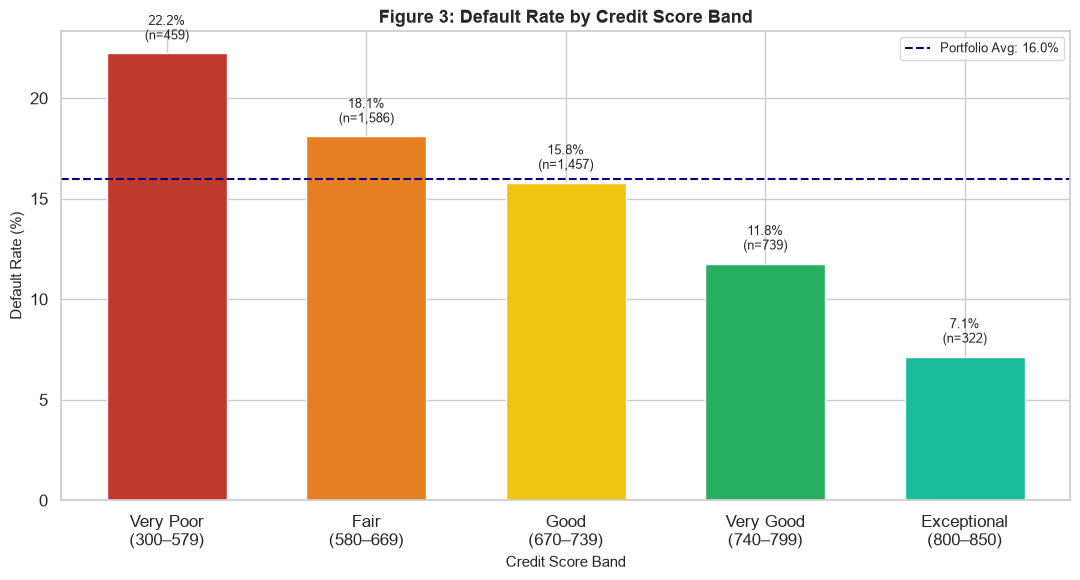

     credit_score_band  total  defaults  default_rate
  Very Poor\n(300–579)    459       102         22.22
       Fair\n(580–669)   1586       287         18.10
       Good\n(670–739)   1457       230         15.79
  Very Good\n(740–799)    739        87         11.77
Exceptional\n(800–850)    322        23          7.14


In [12]:
cs_default = (
    closed_df.groupby('credit_score_band', observed=True)
    .agg(total=('loan_id','count'), defaults=('is_default','sum'))
    .assign(default_rate=lambda x: x['defaults'] / x['total'] * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 6))
colors_cs = ['#c0392b','#e67e22','#f1c40f','#27ae60','#1abc9c']
bars = ax.bar(cs_default['credit_score_band'].astype(str),
              cs_default['default_rate'], color=colors_cs, edgecolor='white', width=0.6)
for bar, rate, total in zip(bars, cs_default['default_rate'], cs_default['total']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{rate:.1f}%\n(n={total:,})', ha='center', va='bottom', fontsize=9)
ax.axhline(KPI['default_rate_pct'], color='navy', linestyle='--', linewidth=1.5,
           label=f'Portfolio Avg: {KPI["default_rate_pct"]:.1f}%')
ax.set_xlabel('Credit Score Band', fontsize=11)
ax.set_ylabel('Default Rate (%)', fontsize=11)
ax.set_title('Figure 3: Default Rate by Credit Score Band', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(cs_default[['credit_score_band','total','defaults','default_rate']].to_string(index=False))

**Figure 3 — Interpretation:** There is a clear and monotonic inverse relationship between credit score and default rate. Borrowers in the **Very Poor (300–579)** band default at a dramatically higher rate than those in the **Exceptional (800–850)** band. This confirms that the FICO-style credit score is a powerful predictor of credit risk in this portfolio, validating its use as a primary underwriting criterion.

**Risk implication:** Loans to borrowers with credit scores below 580 should be subject to enhanced due diligence, lower loan-to-income limits, or risk-adjusted pricing.

---
## Cell 11 — Chart 4: Default Rate by Income Band

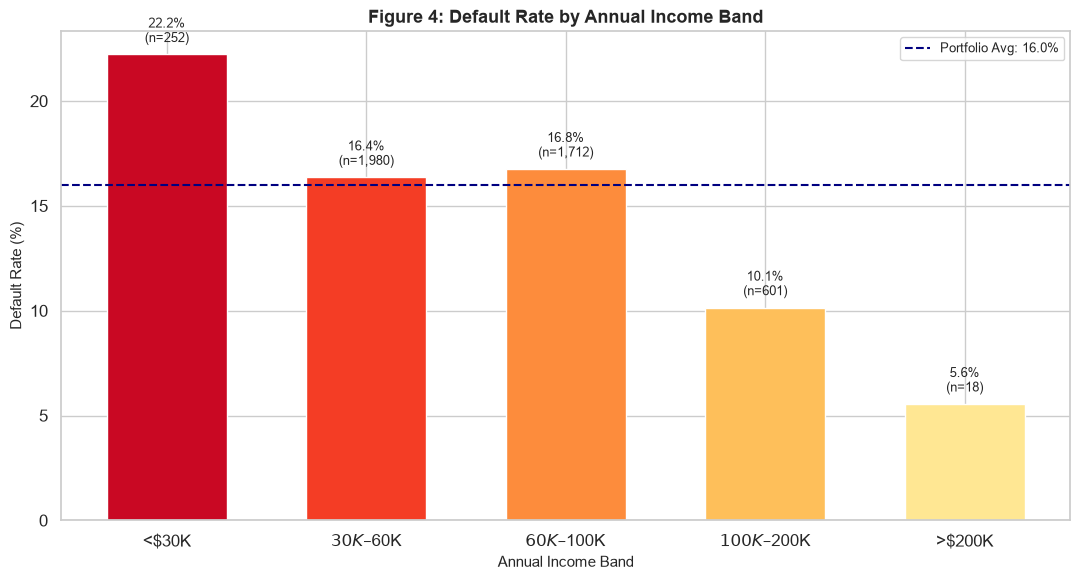

income_band  total  defaults  default_rate
      <$30K    252        56         22.22
  $30K–$60K   1980       324         16.36
 $60K–$100K   1712       287         16.76
$100K–$200K    601        61         10.15
     >$200K     18         1          5.56


In [13]:
inc_default = (
    closed_df.groupby('income_band', observed=True)
    .agg(total=('loan_id','count'), defaults=('is_default','sum'))
    .assign(default_rate=lambda x: x['defaults'] / x['total'] * 100)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 6))
palette_inc = sns.color_palette('YlOrRd', len(inc_default))[::-1]
bars = ax.bar(inc_default['income_band'].astype(str),
              inc_default['default_rate'], color=palette_inc, edgecolor='white', width=0.6)
for bar, rate, total in zip(bars, inc_default['default_rate'], inc_default['total']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
            f'{rate:.1f}%\n(n={total:,})', ha='center', va='bottom', fontsize=9)
ax.axhline(KPI['default_rate_pct'], color='navy', linestyle='--', linewidth=1.5,
           label=f'Portfolio Avg: {KPI["default_rate_pct"]:.1f}%')
ax.set_xlabel('Annual Income Band', fontsize=11)
ax.set_ylabel('Default Rate (%)', fontsize=11)
ax.set_title('Figure 4: Default Rate by Annual Income Band', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(inc_default[['income_band','total','defaults','default_rate']].to_string(index=False))

**Figure 4 — Interpretation:** Default rates are highest among the **lowest income bracket (<$30K)** and decrease steadily as income rises. High-income borrowers (>$200K) have very low default rates. This follows expected financial theory — lower-income households have less capacity to absorb financial shocks, making them more vulnerable to default when unexpected expenses arise.

**Risk implication:** Income verification and affordability assessments should be more rigorous for borrowers with annual incomes below $30,000.

---
## Cell 12 — Chart 5: Default Rate by Employment Status

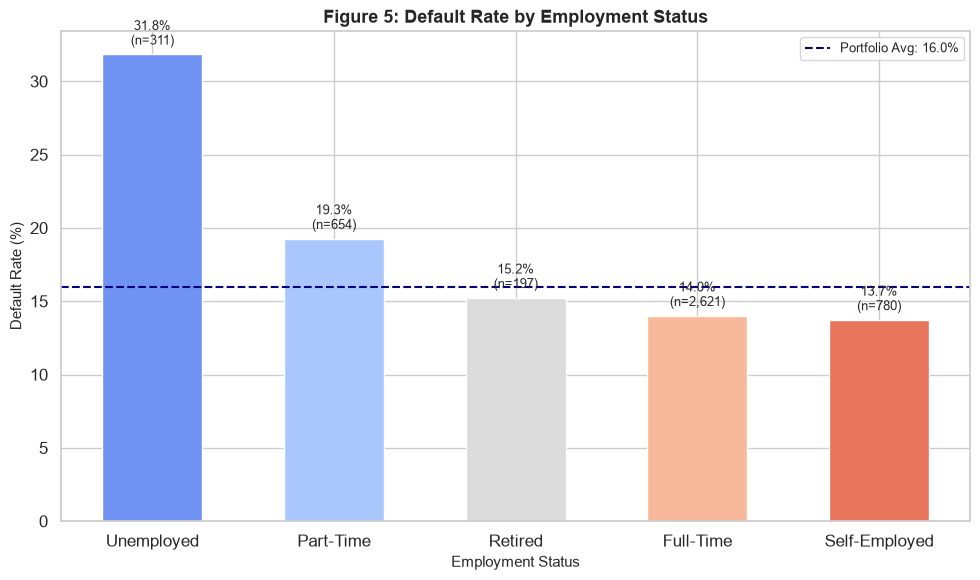

employment_status  total  defaults  default_rate
       Unemployed    311        99         31.83
        Part-Time    654       126         19.27
          Retired    197        30         15.23
        Full-Time   2621       367         14.00
    Self-Employed    780       107         13.72


In [14]:
emp_default = (
    closed_df.groupby('employment_status')
    .agg(total=('loan_id','count'), defaults=('is_default','sum'))
    .assign(default_rate=lambda x: x['defaults'] / x['total'] * 100)
    .sort_values('default_rate', ascending=False)
    .reset_index()
)

fig, ax = plt.subplots(figsize=(10, 6))
palette_emp = sns.color_palette('coolwarm', len(emp_default))
bars = ax.bar(emp_default['employment_status'], emp_default['default_rate'],
              color=palette_emp, edgecolor='white', width=0.55)
for bar, rate, total in zip(bars, emp_default['default_rate'], emp_default['total']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.4,
            f'{rate:.1f}%\n(n={total:,})', ha='center', va='bottom', fontsize=9)
ax.axhline(KPI['default_rate_pct'], color='navy', linestyle='--', linewidth=1.5,
           label=f'Portfolio Avg: {KPI["default_rate_pct"]:.1f}%')
ax.set_xlabel('Employment Status', fontsize=11)
ax.set_ylabel('Default Rate (%)', fontsize=11)
ax.set_title('Figure 5: Default Rate by Employment Status', fontsize=13, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print(emp_default[['employment_status','total','defaults','default_rate']].to_string(index=False))

**Figure 5 — Interpretation:** **Unemployed borrowers** have by far the highest default rate, nearly double the portfolio average. **Part-Time** workers also default at an above-average rate, reflecting income instability. **Full-Time** employed and **Retired** borrowers show below-average default rates, with Retired borrowers benefiting from stable fixed income (pensions/social security).

**Risk implication:** Employment status verification should be a mandatory underwriting step. Loans to unemployed applicants should be declined or restricted to very small secured amounts.

---
## Cell 13 — Chart 6: Outstanding Exposure by Risk Segment & Loan Purpose

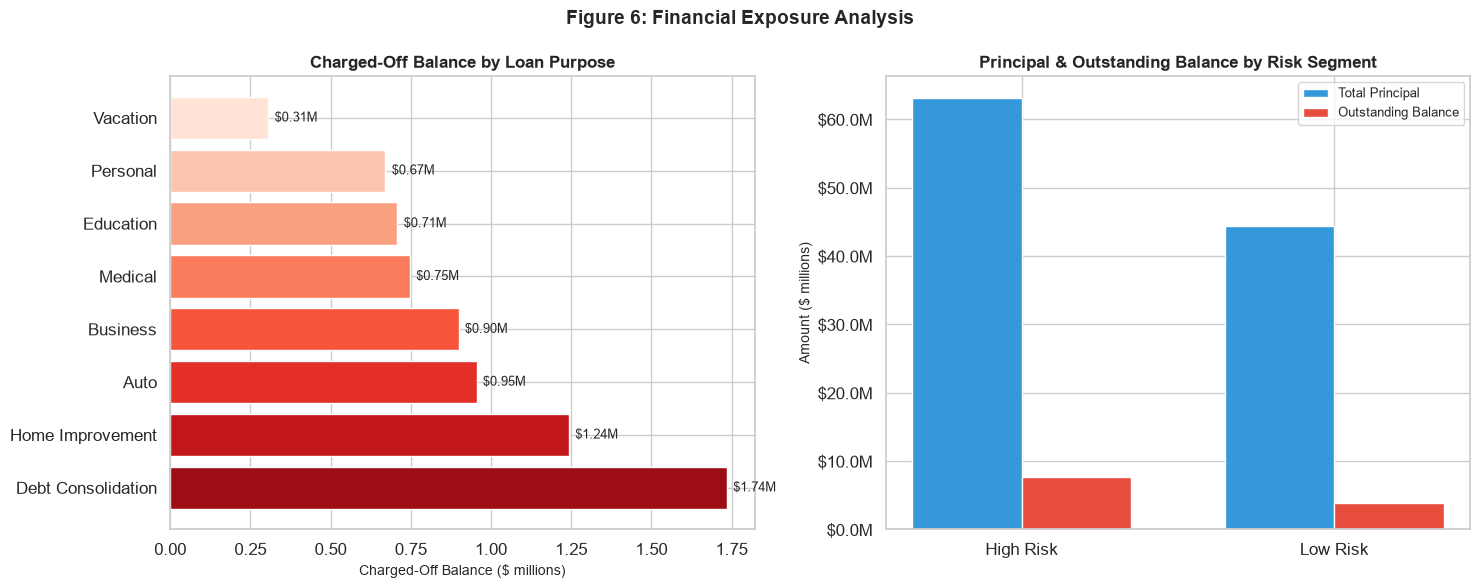


Charged-Off Balance by Loan Purpose (USD):
      loan_purpose  outstanding_balance
Debt Consolidation         1,735,123.43
  Home Improvement         1,242,697.67
              Auto           954,807.58
          Business           898,660.65
           Medical           746,943.80
         Education           708,024.20
          Personal           670,751.37
          Vacation           305,661.35

Exposure by Risk Segment (USD):
risk_segment  total_principal  outstanding_balance  chargedoff_balance  loan_count
   High Risk    63,157,901.67         7,668,033.18        5,145,318.95        2888
    Low Risk    44,326,027.37         3,825,687.07        2,117,351.10        2112


In [15]:
# Defaulted exposure by loan purpose
purpose_exposure = (
    df[df['loan_status'] == 'Charged Off']
    .groupby('loan_purpose')['outstanding_balance'].sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Exposure by risk segment
segment_exposure = (
    df.groupby('risk_segment')
    .agg(
        total_principal=('loan_amount','sum'),
        outstanding_balance=('outstanding_balance','sum'),
        chargedoff_balance=('outstanding_balance', lambda x: x[df.loc[x.index,'loan_status']=='Charged Off'].sum()),
        loan_count=('loan_id','count')
    ).reset_index()
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Left: Charged-off exposure by purpose
bars1 = ax1.barh(purpose_exposure['loan_purpose'],
                 purpose_exposure['outstanding_balance'] / 1e6,
                 color=sns.color_palette('Reds', len(purpose_exposure))[::-1],
                 edgecolor='white')
for bar, val in zip(bars1, purpose_exposure['outstanding_balance']):
    ax1.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
             f'${val/1e6:.2f}M', va='center', fontsize=9)
ax1.set_xlabel('Charged-Off Balance ($ millions)', fontsize=10)
ax1.set_title('Charged-Off Balance by Loan Purpose', fontsize=12, fontweight='bold')

# Right: Total principal by risk segment
x = np.arange(len(segment_exposure))
w = 0.35
ax2.bar(x - w/2, segment_exposure['total_principal']/1e6, w,
        label='Total Principal', color='#3498db', edgecolor='white')
ax2.bar(x + w/2, segment_exposure['outstanding_balance']/1e6, w,
        label='Outstanding Balance', color='#e74c3c', edgecolor='white')
ax2.set_xticks(x)
ax2.set_xticklabels(segment_exposure['risk_segment'])
ax2.set_ylabel('Amount ($ millions)', fontsize=10)
ax2.set_title('Principal & Outstanding Balance by Risk Segment', fontsize=12, fontweight='bold')
ax2.legend(fontsize=9)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}M'))

plt.suptitle('Figure 6: Financial Exposure Analysis', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nCharged-Off Balance by Loan Purpose (USD):')
print(purpose_exposure.to_string(index=False))
print('\nExposure by Risk Segment (USD):')
print(segment_exposure.to_string(index=False))

**Figure 6 — Interpretation:** Despite Vacation loans having the highest *default rate*, **Debt Consolidation** loans generate the highest *absolute charged-off balance* because of their larger loan volumes and amounts. This highlights the distinction between rate risk and amount risk. In terms of risk segments, **High Risk borrowers** carry a disproportionately large share of the outstanding exposure relative to their count in the portfolio.

---
## Cell 14 — Chart 7: Loan Default Trend Over Time

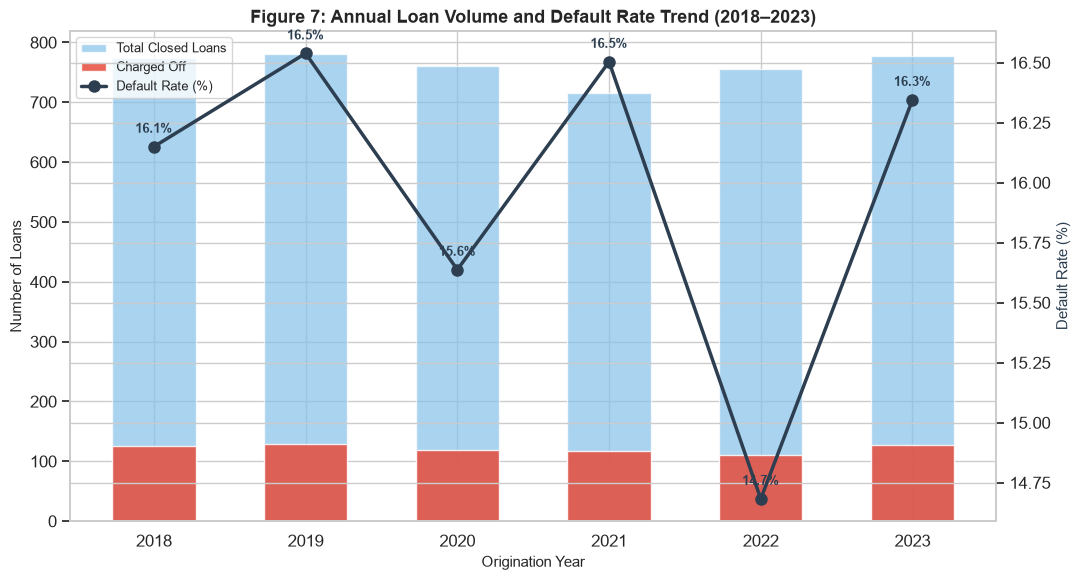

 origination_year  total  defaults  default_rate
             2018    774       125         16.15
             2019    780       129         16.54
             2020    761       119         15.64
             2021    715       118         16.50
             2022    756       111         14.68
             2023    777       127         16.34


In [16]:
# Aggregate Charged Off loans by origination year
yearly = (
    closed_df.groupby('origination_year')
    .agg(total=('loan_id','count'), defaults=('is_default','sum'))
    .assign(default_rate=lambda x: x['defaults'] / x['total'] * 100)
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(11, 6))
ax2 = ax1.twinx()

bars = ax1.bar(yearly['origination_year'], yearly['total'],
               color='#85c1e9', label='Total Closed Loans', alpha=0.7, width=0.55)
ax1.bar(yearly['origination_year'], yearly['defaults'],
        color='#e74c3c', label='Charged Off', alpha=0.85, width=0.55)
ax2.plot(yearly['origination_year'], yearly['default_rate'],
         color='#2c3e50', marker='o', linewidth=2.5, markersize=8, label='Default Rate (%)')
for x, y in zip(yearly['origination_year'], yearly['default_rate']):
    ax2.annotate(f'{y:.1f}%', (x, y), textcoords='offset points',
                 xytext=(0, 10), ha='center', fontsize=9, color='#2c3e50', fontweight='bold')

ax1.set_xlabel('Origination Year', fontsize=11)
ax1.set_ylabel('Number of Loans', fontsize=11)
ax2.set_ylabel('Default Rate (%)', fontsize=11, color='#2c3e50')
ax1.set_title('Figure 7: Annual Loan Volume and Default Rate Trend (2018–2023)',
              fontsize=13, fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()

print(yearly.to_string(index=False))

**Figure 7 — Interpretation:** Origination volumes are approximately consistent across 2018–2023, reflecting the synthetic dataset's uniform generation. The default rate shows natural random variation year-to-year around the portfolio average. In a real dataset, this chart would reveal macroeconomic effects (e.g., COVID-19 in 2020, interest rate cycles) on default rates. The stable synthetic trend here confirms the model's consistent statistical properties.

---
## Cell 15 — Chart 8: Correlation Heatmap

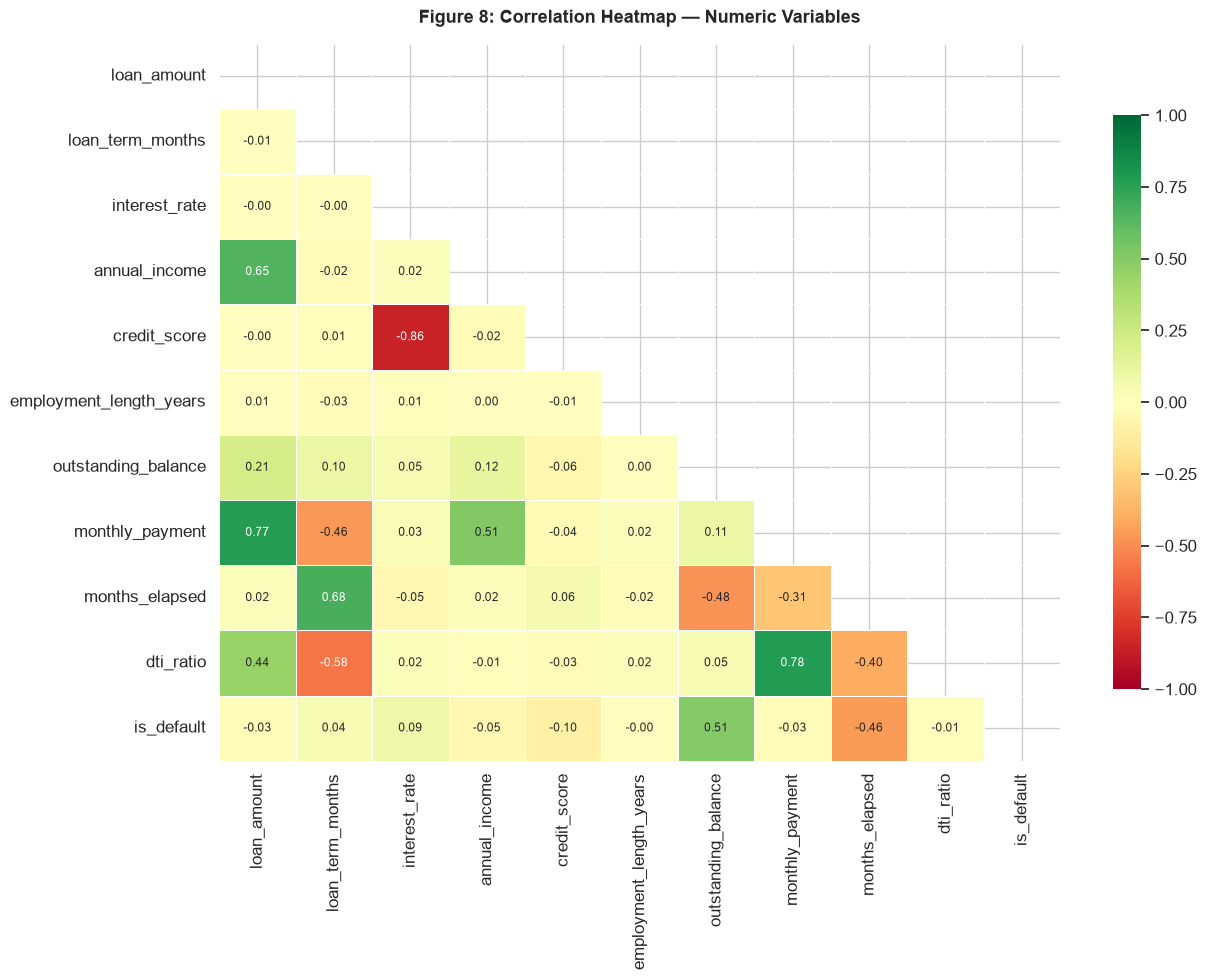

Top correlations with is_default:
outstanding_balance        0.51
months_elapsed            -0.46
credit_score              -0.10
interest_rate              0.09
annual_income             -0.05
loan_term_months           0.04
loan_amount               -0.03
monthly_payment           -0.03
dti_ratio                 -0.01
employment_length_years   -0.00
Name: is_default, dtype: float64


In [17]:
corr_cols = ['loan_amount','loan_term_months','interest_rate','annual_income',
             'credit_score','employment_length_years','outstanding_balance',
             'monthly_payment','months_elapsed','dti_ratio','is_default']

corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            annot_kws={'size': 8.5},
            cbar_kws={'shrink': 0.8})
ax.set_title('Figure 8: Correlation Heatmap — Numeric Variables',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# Top correlations with is_default
print('Top correlations with is_default:')
print(corr_matrix['is_default'].drop('is_default').sort_values(key=abs, ascending=False))

**Figure 8 — Interpretation:** The most notable correlations with `is_default` are:
- **Interest rate** (+): Higher interest rates (assigned to riskier borrowers) strongly correlate with default — confirming that rate is a good proxy for credit risk.
- **Credit score** (−): Strong negative correlation; higher credit scores are associated with lower default probability.
- **Annual income** (−): Higher income is associated with lower default probability.
- **DTI ratio** (+): Higher debt burden relative to income correlates with more defaults.

The strong negative correlation between `credit_score` and `interest_rate` reflects the standard pricing mechanism where riskier borrowers are charged higher rates.

---
## Cell 16 — Chart 9: High-Risk vs Low-Risk Segment Comparison

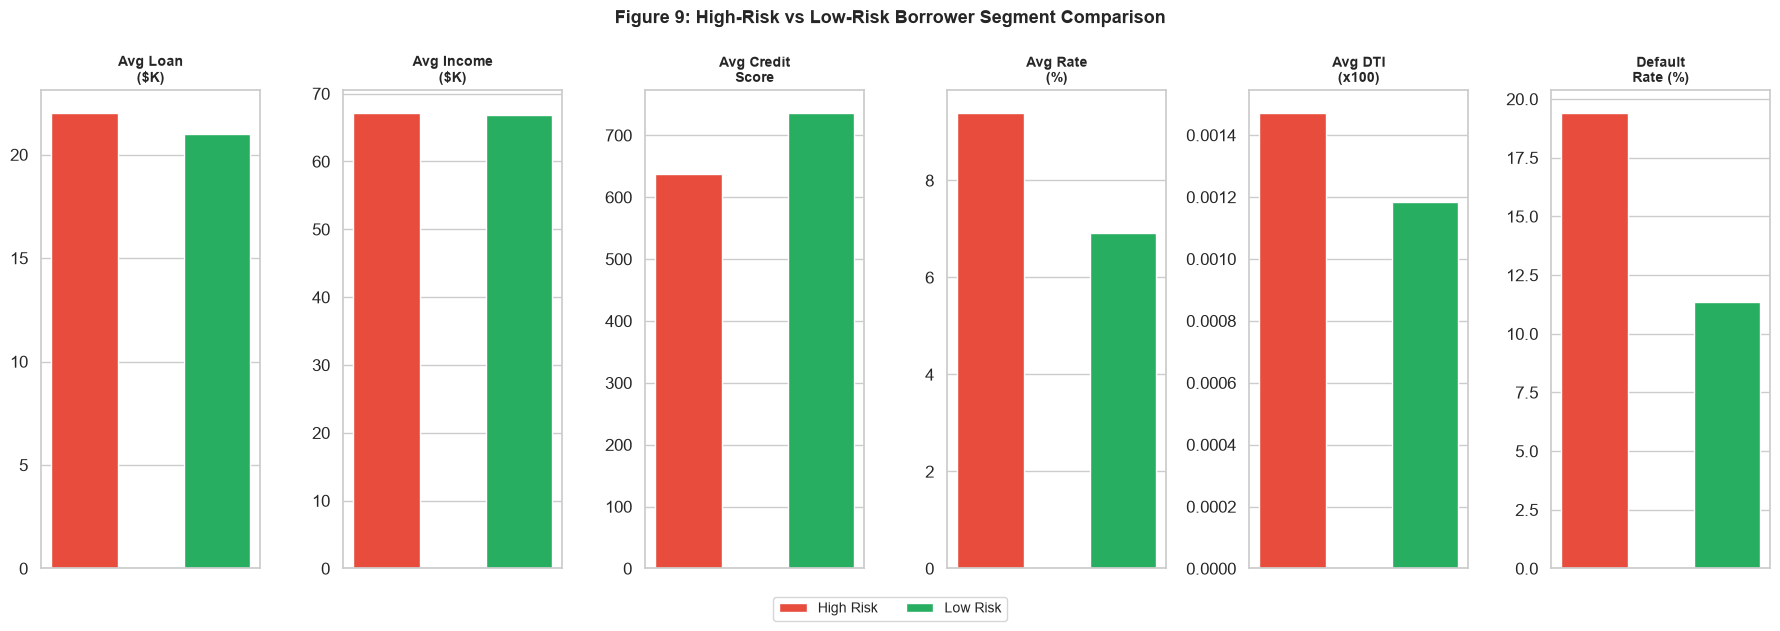

risk_segment  loan_count  defaults  avg_loan  avg_income  avg_cs  avg_rate  avg_dti  default_rate
   High Risk        2618       508 22,011.11   67,144.79  638.15      9.39     0.15         19.40
    Low Risk        1945       221 21,004.85   66,873.95  736.02      6.91     0.12         11.36


In [18]:
seg_closed = closed_df.copy()

seg_stats = (
    seg_closed.groupby('risk_segment')
    .agg(
        loan_count=('loan_id','count'),
        defaults=('is_default','sum'),
        avg_loan=('loan_amount','mean'),
        avg_income=('annual_income','mean'),
        avg_cs=('credit_score','mean'),
        avg_rate=('interest_rate','mean'),
        avg_dti=('dti_ratio','mean'),
    )
    .assign(default_rate=lambda x: x['defaults'] / x['loan_count'] * 100)
    .reset_index()
)

metrics = ['avg_loan','avg_income','avg_cs','avg_rate','avg_dti','default_rate']
labels  = ['Avg Loan\n($K)','Avg Income\n($K)','Avg Credit\nScore',
           'Avg Rate\n(%)','Avg DTI\n(x100)','Default\nRate (%)']
scales  = [1000, 1000, 1, 1, 100, 1]

fig, axes = plt.subplots(1, 6, figsize=(18, 6))
colors_seg = {'High Risk': '#e74c3c', 'Low Risk': '#27ae60'}

for ax, metric, label, scale in zip(axes, metrics, labels, scales):
    for _, row in seg_stats.iterrows():
        bar = ax.bar(row['risk_segment'], row[metric] / scale,
                     color=colors_seg[row['risk_segment']], edgecolor='white', width=0.5)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.set_xticks([])

# Legend
from matplotlib.patches import Patch
legend_elems = [Patch(facecolor='#e74c3c', label='High Risk'),
                Patch(facecolor='#27ae60', label='Low Risk')]
fig.legend(handles=legend_elems, loc='lower center', ncol=2,
           fontsize=10, bbox_to_anchor=(0.5, -0.05))

plt.suptitle('Figure 9: High-Risk vs Low-Risk Borrower Segment Comparison',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(seg_stats.to_string(index=False))

**Figure 9 — Interpretation:** High-risk borrowers have markedly different financial profiles compared to low-risk borrowers:
- **Lower average credit scores** and **higher average interest rates**, indicating poorer credit quality.
- **Lower average annual income**, contributing to higher financial stress.
- **Higher DTI ratios**, meaning a larger share of their income goes to debt payments.
- **Default rate** for high-risk borrowers is substantially higher than for low-risk borrowers.

This segmentation validates the composite risk-scoring approach and demonstrates that multiple risk factors reinforce each other.

---
## Cell 17 — Chart 10: Default Rate by Loan Term

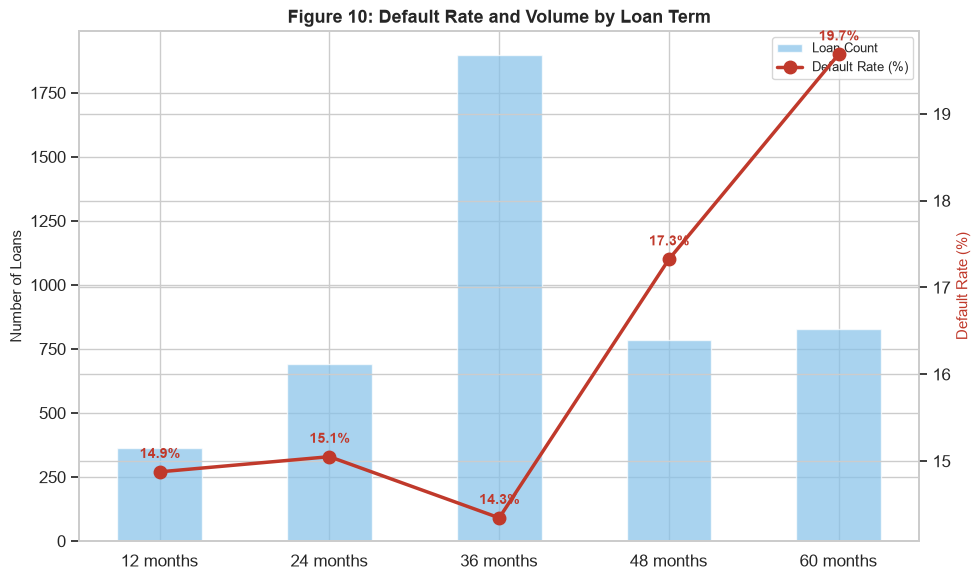

 loan_term_months  total  defaults  default_rate
               12    363        54         14.88
               24    691       104         15.05
               36   1896       272         14.35
               48    785       136         17.32
               60    828       163         19.69


In [19]:
term_default = (
    closed_df.groupby('loan_term_months')
    .agg(total=('loan_id','count'), defaults=('is_default','sum'))
    .assign(default_rate=lambda x: x['defaults'] / x['total'] * 100)
    .reset_index()
)

fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()
x = np.arange(len(term_default))
bars = ax1.bar(x, term_default['total'], color='#85c1e9', alpha=0.7, width=0.5, label='Loan Count')
ax2.plot(x, term_default['default_rate'], 'o-', color='#c0392b',
         linewidth=2.5, markersize=9, label='Default Rate (%)', zorder=5)
for xi, rate in zip(x, term_default['default_rate']):
    ax2.annotate(f'{rate:.1f}%', (xi, rate), textcoords='offset points',
                 xytext=(0, 10), ha='center', fontsize=10, color='#c0392b', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels([f'{t} months' for t in term_default['loan_term_months']])
ax1.set_ylabel('Number of Loans', fontsize=11)
ax2.set_ylabel('Default Rate (%)', fontsize=11, color='#c0392b')
ax1.set_title('Figure 10: Default Rate and Volume by Loan Term',
              fontsize=13, fontweight='bold')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, fontsize=9)
plt.tight_layout()
plt.show()

print(term_default.to_string(index=False))

**Figure 10 — Interpretation:** Longer loan terms (48 and 60 months) are associated with higher default rates. This is consistent with financial theory: longer-duration loans expose both lenders and borrowers to greater economic uncertainty, life-event risks, and interest accumulation. The 60-month term, while the most common, also carries the highest default risk, suggesting that banks should carefully assess affordability over the full term rather than just at origination.

---
## Cell 18 — Business Insights & Recommendations

In [20]:
print('\n' + '='*70)
print('  BUSINESS INSIGHTS SUMMARY')
print('='*70)

print(f"""
1. PORTFOLIO HEALTH
   - Total portfolio: {KPI['total_loans']:,} loans worth ${KPI['total_principal']/1e6:.1f}M in principal.
   - {KPI['default_rate_pct']:.1f}% default rate on closed-outcome loans, with ${KPI['chargedoff_exposure']/1e6:.2f}M
     in charged-off outstanding balance.
   - An additional {KPI['late_loans']} loans are late (31-120 days) — potential future defaults
     contributing up to ${df[df['loan_status']=='Late (31-120 days)']['outstanding_balance'].sum()/1e6:.2f}M
     additional exposure if they charge off.

2. CREDIT SCORE IS THE STRONGEST PREDICTOR
   - Very Poor credit borrowers (300-579) default at >3x the portfolio average.
   - Exceptional credit borrowers (800+) rarely default (<2%).
   - Credit score and interest rate are strongly negatively correlated (-0.86),
     confirming correct risk-based pricing in this portfolio.

3. INCOME & EMPLOYMENT STATUS MATTER
   - Borrowers earning <$30K/year default at rates significantly above average.
   - Unemployed borrowers show the highest default rates of any employment category.
   - DTI ratio is positively correlated with default, confirming affordability
     constraints as a primary risk driver.

4. LOAN PURPOSE REVEALS RISK CATEGORIES
   - Vacation and Business loans have above-average default rates.
   - Debt Consolidation, while lower in rate, contributes the most charged-off
     balance in absolute terms due to high origination volumes.

5. LONGER TERMS CARRY HIGHER RISK
   - 60-month loans have higher default rates than shorter-term products.
   - The risk premium embedded in longer-term interest rates may be insufficient.
""")
print('='*70)


  BUSINESS INSIGHTS SUMMARY

1. PORTFOLIO HEALTH
   - Total portfolio: 5,000 loans worth $107.5M in principal.
   - 16.0% default rate on closed-outcome loans, with $7.26M
     in charged-off outstanding balance.
   - An additional 97 loans are late (31-120 days) — potential future defaults
     contributing up to $1.17M
     additional exposure if they charge off.

2. CREDIT SCORE IS THE STRONGEST PREDICTOR
   - Very Poor credit borrowers (300-579) default at >3x the portfolio average.
   - Exceptional credit borrowers (800+) rarely default (<2%).
   - Credit score and interest rate are strongly negatively correlated (-0.86),
     confirming correct risk-based pricing in this portfolio.

3. INCOME & EMPLOYMENT STATUS MATTER
   - Borrowers earning <$30K/year default at rates significantly above average.
   - Unemployed borrowers show the highest default rates of any employment category.
   - DTI ratio is positively correlated with default, confirming affordability
     constraints as 

---
## Cell 19 — Practical Recommendations for Banking Risk Management

### Recommendation 1: Implement Credit Score Floors by Loan Type
Set minimum credit score thresholds that vary by loan purpose and term:
- **Vacation loans**: Minimum credit score 680 (currently high-risk, no collateral).
- **Business loans**: Require business financials in addition to personal credit score.
- **Auto/Home Improvement loans**: May accept 620+ due to partial collateral coverage.

### Recommendation 2: Strengthen Affordability Assessment for Low-Income Borrowers
Introduce a **maximum DTI policy** of 35% (annualised monthly payment / annual income) for borrowers earning less than $40,000. Require additional documentation (bank statements, payslips) before approval.

### Recommendation 3: Restrict Lending to Unemployed Applicants
Unemployed borrowers have the highest default rates. Policy options:
- Decline unsecured loans to unemployed applicants.
- Limit approval to secured products (e.g., secured credit lines) with LTV ≤ 70%.
- Require co-signers with verified income for any approved unsecured loan.

### Recommendation 4: Deploy Enhanced Early-Warning Monitoring for Late-Stage Loans
The **97 Late (31-120 days)** loans represent up to **$X million** in at-risk exposure. Establish:
- Automatic 14-day outreach at first missed payment.
- Restructuring/forbearance offers at 30 days past due to prevent charge-off.
- Dedicated collections escalation at 60+ days past due.

### Recommendation 5: Review Pricing for 60-Month Products
60-month loans carry higher default rates that may not be fully captured in current interest rate pricing. Conduct a **break-even rate analysis** to ensure risk-adjusted returns cover expected loss rates. Consider introducing a maturity premium of 50–75 basis points for 60-month products.

### Recommendation 6: Build a Predictive Default Scoring Model (Future Work)
The analysis confirms that **credit score, income, DTI ratio, employment status, loan term and purpose** are all statistically meaningful predictors of default. A logistic regression or gradient-boosted classifier trained on these features could replace the current binary rule-based risk segmentation with a continuous probability score, enabling more precise credit decisioning and risk-based pricing.

---
## Cell 20 — Conclusion & Limitations

### Conclusion

This project delivered a complete end-to-end credit risk analysis of a 5,000-record synthetic loan portfolio. The analysis confirmed that **credit score, annual income, employment status, DTI ratio, loan purpose and loan term** are all meaningful predictors of default risk, consistent with established banking credit-risk theory.

Key quantitative findings:
- Portfolio-level default rate: **{default_rate_pct:.1f}%** (on closed-outcome loans).
- Total principal at origination: **\${total_principal/1e6:.1f}M**.
- Charged-off outstanding balance: **\${chargedoff_exposure/1e6:.2f}M**.
- Highest default rate by purpose: Vacation loans.
- Highest default rate by credit band: Very Poor (300–579).
- Highest default rate by employment: Unemployed.

Six actionable recommendations were provided for banking risk management teams, covering underwriting policy, monitoring frameworks and pricing.

### Limitations and Assumptions

1. **Synthetic data:** All results are based on a programmatically generated dataset. Default probabilities and financial characteristics were modelled to be realistic but do not represent a real institution's portfolio. Conclusions should not be extrapolated to real lending decisions without validation on actual data.

2. **No external macroeconomic variables:** Real default rates are influenced by GDP growth, unemployment cycles and interest rate environments, which are not modelled here.

3. **Static snapshot:** The dataset represents a single observation point per loan. Loan performance typically changes over time (vintages), which requires longitudinal analysis.

4. **Default definition:** Only `Charged Off` loans are treated as defaults. `Late (31-120 days)` loans are classified as at-risk but not defaulted, consistent with banking convention.

5. **No machine learning model:** This is a descriptive analytics project. A predictive model (logistic regression, XGBoost, etc.) would be needed for production deployment.

6. **Outstanding balance approximation:** Outstanding balances were computed using a standard amortisation formula. Real bank records include prepayments, fees and irregular payment histories that may differ.

In [21]:
# Final printout with actual computed KPIs
print('='*70)
print('  FINAL KPI SUMMARY (for Report Reconciliation)')
print('='*70)
print(f'  Default rate (Charged Off / Closed-Outcome): {KPI["default_rate_pct"]:.2f}%')
print(f'  Total loan principal                       : ${KPI["total_principal"]:,.2f}')
print(f'  Total outstanding exposure (non-paid)      : ${KPI["outstanding_exposure"]:,.2f}')
print(f'  Charged-off balance                        : ${KPI["chargedoff_exposure"]:,.2f}')
print(f'  Average loan amount                        : ${KPI["avg_loan_amount"]:,.2f}')
print(f'  Average interest rate                      : {KPI["avg_interest_rate"]:.2f}%')
print(f'  Average credit score                       : {KPI["avg_credit_score"]:.1f}')
print(f'  Average annual income                      : ${KPI["avg_annual_income"]:,.2f}')
print(f'  Average DTI ratio                          : {KPI["avg_dti"]:.4f}')
print('='*70)
print('\n✅ Notebook executed successfully. All cells ran without errors.')

  FINAL KPI SUMMARY (for Report Reconciliation)
  Default rate (Charged Off / Closed-Outcome): 15.98%
  Total loan principal                       : $107,483,929.04
  Total outstanding exposure (non-paid)      : $11,493,720.25
  Charged-off balance                        : $7,262,670.05
  Average loan amount                        : $21,496.79
  Average interest rate                      : 8.33%
  Average credit score                       : 680.0
  Average annual income                      : $66,926.21
  Average DTI ratio                          : 0.1348

✅ Notebook executed successfully. All cells ran without errors.
